# Day 2 - Preprocessing (UNSW-NB15)

Steps in this notebook:
1. load and clean
2. choose the target (multi-class or binary)
3. train / validation / test split
4. label encoding
5. normalization
6. Mutual Information feature selection
7. class imbalance
8. save the files for Member B and for the models on Day 3

The functions live in `src/preprocess.py`. Here we call them one by one so you can see what each step does.

In [1]:
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# make the src folder importable
sys.path.append(os.path.abspath("../src"))
import preprocess as pp

os.makedirs("figures", exist_ok=True)

## Settings

- `MODE = "multiclass"` predicts the attack type (10 classes).
- `MODE = "binary"` predicts normal or attack.

Use the same choice you wrote in `data_notes.md`.

In [2]:
MODE = "multiclass"     # or "binary"
TOP_K = 30              # number of features to keep
print("Mode:", MODE, "| top features:", TOP_K)

Mode: multiclass | top features: 30


## 1. Load and clean

In [3]:
train_full, test = pp.load_raw()
print("Raw train:", train_full.shape, "| raw test:", test.shape)

train_full = pp.basic_clean(train_full, drop_duplicates=True)
test = pp.basic_clean(test, drop_duplicates=False)
print("After cleaning train:", train_full.shape, "| test:", test.shape)

Raw train: (175341, 45) | raw test: (82332, 45)
Duplicates removed: 67601
After cleaning train: (107740, 44) | test: (82332, 44)


What the cleaning did:
- dropped the `id` column
- removed duplicate rows from train (so the same row cannot be in both train and validation)
- replaced infinite and missing values with 0

Duplicates are only removed from train. The test file is left as it is.

## 2. Features (X) and target (y)

In [4]:
X_full, y_full = pp.make_xy(train_full, MODE)
X_test, y_test = pp.make_xy(test, MODE)
feature_columns = list(X_full.columns)

print("Number of features:", len(feature_columns))
print(y_full.value_counts())

Number of features: 42
attack_cat
Normal            51890
Exploits          19844
Fuzzers           16150
Reconnaissance     7522
Generic            4181
DoS                3806
Analysis           1594
Backdoor           1535
Shellcode          1091
Worms               127
Name: count, dtype: int64


## 3. Train / validation split

In [5]:
X_train, X_val, y_train, y_val = pp.split_train_val(X_full, y_full)
print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)

# every class should appear in all three parts
print()
print(pd.DataFrame({
    "train": y_train.value_counts(),
    "val": y_val.value_counts(),
    "test": y_test.value_counts(),
}))

Train: (91579, 42) | Val: (16161, 42) | Test: (82332, 42)

                train   val   test
attack_cat                        
Analysis         1355   239    677
Backdoor         1305   230    583
DoS              3235   571   4089
Exploits        16867  2977  11132
Fuzzers         13727  2423   6062
Generic          3554   627  18871
Normal          44107  7783  37000
Reconnaissance   6394  1128   3496
Shellcode         927   164    378
Worms             108    19     44


The split is stratified, so each class has the same share in train and validation.
The encoders and scaler below are fitted on **train only**, so nothing leaks from validation or test.

## 4. Label encoding

In [6]:
encoders = pp.fit_encoders(X_train)
for col, le in encoders.items():
    print(col, "->", len(le.classes_), "values:", list(le.classes_)[:8])

X_train_enc = pp.apply_encoders(X_train, encoders)
X_val_enc = pp.apply_encoders(X_val, encoders)
X_test_enc = pp.apply_encoders(X_test, encoders)

target_encoder, y_train_e, y_val_e, y_test_e = pp.encode_target(y_train, y_val, y_test)
class_names = list(target_encoder.classes_)
print()
for i, name in enumerate(class_names):
    print(i, "=", name)

# values never seen in train become -1
print()
print("Unseen values in test:", (X_test_enc[pp.CATEGORICAL_COLS] == -1).sum().to_dict())

proto -> 133 values: ['3pc', 'a/n', 'aes-sp3-d', 'any', 'argus', 'aris', 'arp', 'ax.25']
service -> 13 values: ['-', 'dhcp', 'dns', 'ftp', 'ftp-data', 'http', 'irc', 'pop3']
state -> 7 values: ['CON', 'ECO', 'FIN', 'INT', 'REQ', 'RST', 'URN']

0 = Analysis
1 = Backdoor
2 = DoS
3 = Exploits
4 = Fuzzers
5 = Generic
6 = Normal
7 = Reconnaissance
8 = Shellcode
9 = Worms

Unseen values in test: {'proto': 0, 'service': 0, 'state': 5}


## 5. Normalization (MinMaxScaler)

In [7]:
scaler = pp.fit_scaler(X_train_enc)
X_train_s = pp.apply_scaler(X_train_enc, scaler)
X_val_s = pp.apply_scaler(X_val_enc, scaler)
X_test_s = pp.apply_scaler(X_test_enc, scaler)

print("Train min:", X_train_s.values.min(), "| max:", X_train_s.values.max())
print("Test  min:", X_test_s.values.min(), "| max:", X_test_s.values.max())

Train min: 0.0 | max: 1.0
Test  min: 0.0 | max: 1.0


All values are now between 0 and 1. Values in validation or test that go past the training range are cut back to 0 or 1.

## 6. Mutual Information feature selection

Mutual Information measures how much each feature tells us about the target. A higher score means a more useful feature.
It is slow on 150,000 rows, so it runs on a random sample of 20,000 rows. This cell can take a minute or two.

In [8]:
ranking = pp.mutual_info_ranking(X_train_s, y_train_e, X_train_encoded=X_train_enc)
print(ranking.head(15))

sbytes          0.806989
dbytes          0.633992
smean           0.590417
dmean           0.519563
sttl            0.511206
sload           0.469814
dttl            0.457753
ct_state_ttl    0.454622
rate            0.413920
dload           0.412953
dpkts           0.410633
dinpkt          0.409830
dur             0.382273
synack          0.367655
tcprtt          0.364618
dtype: float64


Kept 30 of 42 features
['dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_dst_src_ltm', 'ct_src_ltm', 'ct_srv_dst']


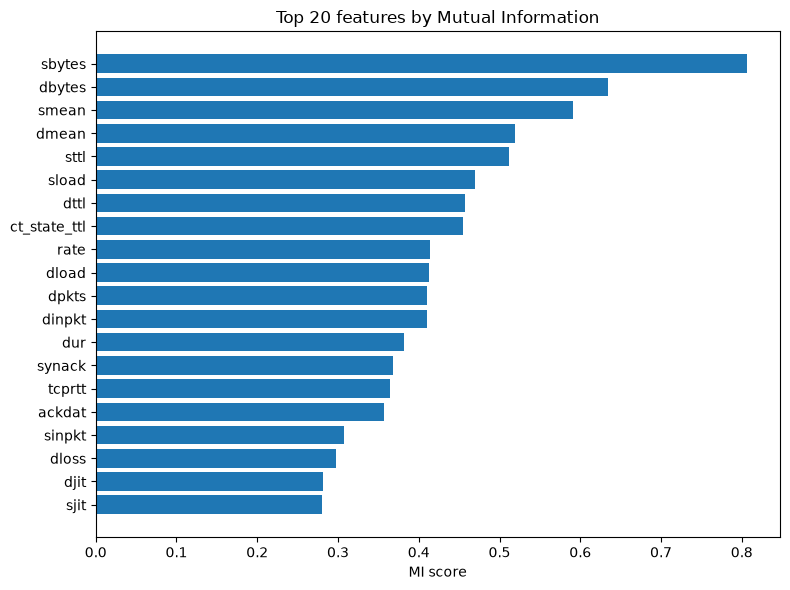

In [9]:
selected = pp.pick_features(ranking, feature_columns, TOP_K)
print("Kept", len(selected), "of", len(feature_columns), "features")
print(selected)

top = ranking.head(20)[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values)
plt.title("Top 20 features by Mutual Information")
plt.xlabel("MI score")
plt.tight_layout()
plt.savefig("figures/mutual_info_top20.png", dpi=150)
plt.show()

## 7. Class imbalance

Two options:
- **class weights** (used here): small classes get a bigger weight during training, so the model pays more attention to them.
- **SMOTE** (optional, `USE_SMOTE` in `preprocess.py`): creates extra rows for small classes. It makes the training data much bigger, so it is off by default.

The weights are saved now and used when we train the models on Day 3.

In [10]:
class_weights = pp.get_class_weights(y_train_e)
for i, w in class_weights.items():
    print(class_names[i], "-> weight", round(w, 2))

Analysis -> weight 6.76
Backdoor -> weight 7.02
DoS -> weight 2.83
Exploits -> weight 0.54
Fuzzers -> weight 0.67
Generic -> weight 2.58
Normal -> weight 0.21
Reconnaissance -> weight 1.43
Shellcode -> weight 9.88
Worms -> weight 84.8


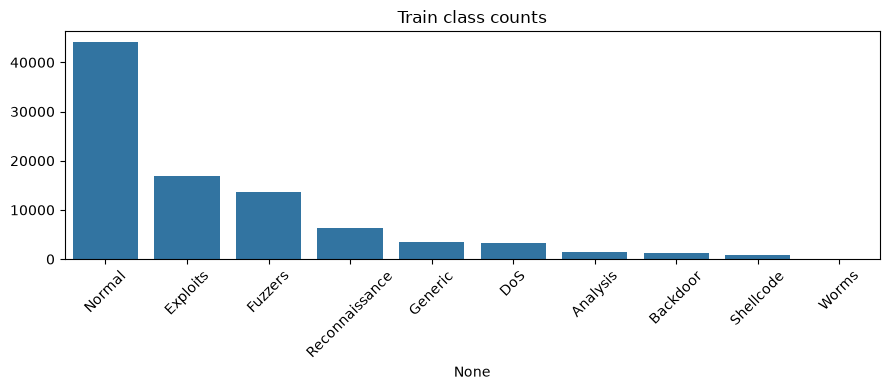

In [11]:
counts = pd.Series(y_train_e).map(lambda i: class_names[i]).value_counts()
plt.figure(figsize=(9, 4))
sns.barplot(x=counts.index, y=counts.values)
plt.xticks(rotation=45)
plt.title("Train class counts")
plt.tight_layout()
plt.savefig("figures/train_class_counts.png", dpi=150)
plt.show()

## 8. Build the final arrays and save

In [12]:
Xtr = X_train_s[selected].values.astype("float32")
Xva = X_val_s[selected].values.astype("float32")
Xte = X_test_s[selected].values.astype("float32")

arrays = {
    "X_train": Xtr, "y_train": y_train_e,
    "X_val": Xva, "y_val": y_val_e,
    "X_test": Xte, "y_test": y_test_e,
}
artifacts = {
    "encoders": encoders, "target_encoder": target_encoder, "scaler": scaler,
    "feature_columns": feature_columns, "selected_features": selected,
    "class_names": class_names, "class_weights": class_weights,
}
meta = {
    "mode": MODE, "top_k": TOP_K, "use_smote": False,
    "n_features": len(selected), "n_classes": len(class_names),
    "train_rows": int(len(Xtr)), "val_rows": int(len(Xva)), "test_rows": int(len(Xte)),
}

pp.save_everything(arrays, artifacts, meta)
ranking.to_csv(pp.ARTIFACT_DIR / "mutual_info_ranking.csv", header=["mi_score"])
print("Saved.")
print(os.listdir(pp.PROCESSED_DIR))
print(os.listdir(pp.ARTIFACT_DIR))

Saved.
['.gitkeep', 'X_test.npy', 'X_train.npy', 'X_val.npy', 'y_test.npy', 'y_train.npy', 'y_val.npy']
['class_names.json', 'class_weights.json', 'feature_columns.json', 'feature_encoders.joblib', 'meta.json', 'mutual_info_ranking.csv', 'scaler.joblib', 'selected_features.json', 'target_encoder.joblib']


## 9. Sanity checks

In [13]:
for name, arr in arrays.items():
    print(name, arr.shape, arr.dtype)

print()
print("NaN in X_train:", np.isnan(Xtr).any())
print("X_train min/max:", Xtr.min(), Xtr.max())
print("Classes in train / val / test:",
      len(np.unique(y_train_e)), len(np.unique(y_val_e)), len(np.unique(y_test_e)))
print("Features match the saved list:", Xtr.shape[1] == len(selected))

X_train (91579, 30) float32
y_train (91579,) int64
X_val (16161, 30) float32
y_val (16161,) int64
X_test (82332, 30) float32
y_test (82332,) int64

NaN in X_train: False
X_train min/max: 0.0 1.0
Classes in train / val / test: 10 10 10
Features match the saved list: True


## 10. Test the function Member B will use

`preprocess_input` takes raw rows (the original column names) and gives back the numbers the model expects.
Its result for the first 5 test rows must match the saved `X_test`.

In [14]:
raw_test = pd.read_csv(pp.RAW_DIR / "UNSW_NB15_testing-set.csv", encoding="utf-8-sig")
out = pp.preprocess_input(raw_test.head(5))
print("Output shape:", out.shape)

saved = np.load(pp.PROCESSED_DIR / "X_test.npy")
print("Matches saved X_test:", np.allclose(saved[:5], out))

# one row as a dictionary, like a web form would send
one_row = raw_test.iloc[0].to_dict()
print("Single row shape:", pp.preprocess_input(one_row).shape)

Output shape: (5, 30)
Matches saved X_test: True
Single row shape: (1, 30)


Note: the match check only works when no duplicates were dropped from the first rows of the test file.
This is true here because duplicates are only removed from train.

## Summary for data_notes.md and for Member B

In [15]:
print("Mode:", MODE)
print("Features kept:", len(selected), "of", len(feature_columns))
print("Classes:", class_names)
print("Train / val / test rows:", len(Xtr), len(Xva), len(Xte))
print("Smallest class in train:", counts.idxmin(), counts.min())
print("Selected features:", selected)

Mode: multiclass
Features kept: 30 of 42
Classes: ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Normal', 'Reconnaissance', 'Shellcode', 'Worms']
Train / val / test rows: 91579 16161 82332
Smallest class in train: Worms 108
Selected features: ['dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_dst_src_ltm', 'ct_src_ltm', 'ct_srv_dst']


## My notes (write in your own words)

- Why did I use Mutual Information?
- Why are the encoders and scaler fitted on train only?
- How did I handle the imbalance?